# GPU-trained character-level Transformer spell-checker

**Safe rerun:** use this saved `Assignment 2/spell_checker.ipynb`, not an older unsaved editor buffer. Interrupt any existing training and restart the kernel before rerunning. The default float32 reuse path is `outputs/optimized-float32`, which contains the intact completed 30-epoch checkpoint. With `REUSE_TRAINED = True`, missing or incompatible files raise an error; they never start fresh training. A fresh float32 GPU run requires `REUSE_TRAINED = False` and defaults to the separate `outputs/full-retrain` directory. `SPELLCHECK_OUTPUT_DIR`, if set, overrides these paths.

Translate noisy text (`fr`) into corrected text (`en`) using a TensorFlow/Keras encoder-decoder Transformer trained **from scratch** on the [GitHub Typo Corpus](https://github.com/mhagiwara/github-typo-corpus). These suffixes denote correction direction, not French and English.

**Modes.** `MODE = 'full'` is the default GPU experiment: four Transformer blocks per side, all training lengths up to 512 characters, and up to 30 epochs with early stopping. Full mode requires a working TensorFlow GPU and verifies GPU execution before training. `MODE = 'cpu'` retains the reduced two-block, two-epoch, 128-character experiment; `MODE = 'smoke'` is a tiny pipeline test, not evidence of correction quality. `REUSE_TRAINED = True` reuses a matching completed experiment rather than repeating an eight-hour run. Set it to `False` for fresh training. Dataset hashes, split indices, architecture, precision and runtime versions must match. Batch progress is appended to `training_progress.log`. Even a trained model cannot guarantee errorless output.

## Measured optimizations
On this NVIDIA GB10 GPU, a 20,000-pair input-pipeline pass fell from 2.23 s (Python generator) to 0.85 s (pre-encoded tensors in host memory). A warmed-up 256-batch GPU-training benchmark, including masked accuracy, took 22.50 s originally, 20.78 s with tensor input and 32 steps per Keras execution, and 18.36 s with bfloat16 as well. These are bounded throughput measurements, not a rerun of the full 30-epoch experiment or a guarantee of the same end-to-end speedup. Pre-encoding trades host memory for eliminating repeated Python tokenization. Length buckets still retain every pair and never truncate. Batched native edit distances took 0.318 s versus 10.355 s in Python for all 5,659 saved predictions, with identical results. Full held-out float32 decoding took 240.0 s versus the original 351.2 s; all predictions and evaluation metrics remained identical. Decoding retains batches of 64: larger batches were slower in the measured held-out sample. XLA stays disabled because it did not consistently help long sequences.

The default `PRECISION_POLICY = 'float32'` preserves the existing trained checkpoint. For a new GPU experiment, choose `'mixed_bfloat16'` and `REUSE_TRAINED = False`; its default directory is `outputs/full-mixed_bfloat16`, so the original float32 results survive. Logits and loss remain float32 for stability. An explicit `SPELLCHECK_OUTPUT_DIR` override takes precedence. Mixed precision can change predictions and needs its own evaluation. Single-input decoding delegates to the same tested batch decoder; character edit distances use TensorFlow's batched native implementation, not nested Python loops. Safety checks and rubric analysis remain in the notebook.

**Independent evaluation.** Within the supplied development split, all rows with the same noisy input stay together. Inputs appearing in training are excluded from development selection and evaluation. Seeded source groups supply at least 2,000 checkpoint-selection rows (eight in smoke mode); complete groups can exceed that target. Full mode evaluates every remaining eligible development row; CPU mode samples up to 4,000. Duplicate counts, excluded rows and the actual split sizes are reported. The supplied train/development split is never reconstructed from `all.tsv`.

## Environment
Use Python 3.11 or 3.12 and a TensorFlow-compatible kernel. On this NVIDIA GB10 machine, select **NLP AI-574 (GB10 GPU)** from **Select Another Kernel > Jupyter Kernel**. This registered kernel points directly to `/home/nizare/GitHub/dl-ai570/.venv/bin/python`, which has Matplotlib, TensorFlow 2.17.0 with NVIDIA CUDA support, and Keras 3.15.0. Preserve this working vendor GPU installation rather than replacing it with a generic wheel. The notebook kernel selection is separate from the workspace Python interpreter; changing notebook metadata alone does not switch an already-running kernel. Restart after selecting it. The first code cell prints its actual interpreter and reports missing packages before importing the model dependencies.

On another machine, install into your chosen compatible kernel with `%pip install tensorflow==2.20.0 matplotlib==3.11.2`; Jupyter also needs `ipykernel`. Restart the kernel after installation. Do not install into an unrelated Python environment to repair a notebook import. The notebook uses Keras 3 through `tf.keras` and no pretrained weights or external model downloads.

In [1]:
import hashlib
import importlib.util
import json
import math
import os
import string
import sys
import tempfile
import time
from collections import Counter
from itertools import zip_longest
from pathlib import Path
from IPython.display import Markdown, display

print('Notebook Python:', sys.executable, flush=True)
missing_modules = [name for name in ('matplotlib', 'numpy', 'tensorflow') if importlib.util.find_spec(name) is None]
if missing_modules:
    raise ModuleNotFoundError(f"Notebook kernel {sys.executable} is missing: {', '.join(missing_modules)}. "
                              'Select Another Kernel > Jupyter Kernel > NLP AI-574 (GB10 GPU), then restart. '
                              'On another machine, install these dependencies into the selected compatible kernel.')

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

MODE = 'full'  # GPU experiment; 'smoke' tests the pipeline, 'cpu' is an explicit reduced fallback.
REUSE_TRAINED = True  # Reuse the completed experiment; set False for fresh training.
PRECISION_POLICY = 'float32'  # 'mixed_bfloat16' opts into a separate GPU-training experiment.
if PRECISION_POLICY not in {'float32', 'mixed_bfloat16'}:
    raise ValueError('PRECISION_POLICY must be float32 or mixed_bfloat16')
tf.keras.mixed_precision.set_global_policy(PRECISION_POLICY)
if MODE not in {'smoke', 'cpu', 'full'}:
    raise ValueError("MODE must be 'smoke', 'cpu' or 'full'")
SEED = 574
MAX_CHARS = 512  # Longest sequence in the supplied corpus.
MODEL_MAX_CHARS = 128 if MODE == 'cpu' else MAX_CHARS  # Longest input/output the model is trained and used for.
DECODE_MARGIN = 50  # Generated text may exceed the input length by at most this many characters.
VALIDATION_PAIRS, CPU_EVALUATION_PAIRS = 2000, 4000
SPACE = '\u2581'
PAD, BOS, EOS = 0, 1, 2
ALLOWED = set(string.ascii_letters + string.digits + ".,!?'#-" + SPACE)
gpu_devices = tf.config.list_physical_devices('GPU')
for device in gpu_devices:
    tf.config.experimental.set_memory_growth(device, True)
if MODE == 'full' and not gpu_devices:
    raise RuntimeError('Full mode requires a TensorFlow GPU. Select the GPU kernel or choose cpu/smoke explicitly.')
if gpu_devices:
    with tf.device('/GPU:0'):
        gpu_probe = tf.matmul(tf.ones((32, 32)), tf.ones((32, 32)))
    if 'GPU' not in gpu_probe.device or float(tf.reduce_sum(gpu_probe)) != 32768.0:
        raise RuntimeError('TensorFlow GPU execution verification failed')
    print('Verified GPU computation:', gpu_probe.device)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

PROJECT_DIR = Path.cwd() / 'Assignment 2' if (Path.cwd() / 'Assignment 2').is_dir() else Path.cwd()
DATA_DIR = Path(os.environ.get('SPELLCHECK_DATA_DIR', str(PROJECT_DIR / 'gtc'))).expanduser().resolve()
DATA_FILES = ('train.tok.fr.txt', 'train.tok.en.txt', 'dev.tok.fr.txt', 'dev.tok.en.txt')
missing_files = [str(DATA_DIR / name) for name in DATA_FILES if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError('Missing original aligned corpus files: ' + ', '.join(missing_files)
                            + '. Restore the supplied files or set SPELLCHECK_DATA_DIR; do not reconstruct all.tsv.')


def dataset_fingerprints(directory):
    fingerprints = {}
    for name in DATA_FILES:
        with (directory / name).open('rb') as stream:
            fingerprints[name] = hashlib.file_digest(stream, 'sha256').hexdigest()
    return fingerprints


dataset_sha256 = dataset_fingerprints(DATA_DIR)
run_name = MODE if PRECISION_POLICY == 'float32' else f'{MODE}-{PRECISION_POLICY}'
if MODE == 'full' and PRECISION_POLICY == 'float32':
    run_name = 'optimized-float32' if REUSE_TRAINED else 'full-retrain'
OUTPUT_DIR = Path(os.environ.get('SPELLCHECK_OUTPUT_DIR', str(PROJECT_DIR / 'outputs' / run_name)))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SETTINGS = {
    'smoke': dict(d_model=32, num_heads=2, ff_dim=64, num_layers=1, batch_size=8, epochs=2, warmup=10, patience=5),
    'cpu': dict(d_model=128, num_heads=4, ff_dim=512, num_layers=2, batch_size=64, epochs=2, warmup=1500, patience=2),
    'full': dict(d_model=128, num_heads=4, ff_dim=512, num_layers=4, batch_size=32, epochs=30, warmup=4000, patience=5),
}[MODE]
CONFIG = dict(vocab_size=0, max_chars=MODEL_MAX_CHARS, d_model=SETTINGS['d_model'], num_heads=SETTINGS['num_heads'],
              ff_dim=SETTINGS['ff_dim'], num_layers=SETTINGS['num_layers'], dropout=0.1)
BATCH_SIZE, EPOCHS = SETTINGS['batch_size'], SETTINGS['epochs']
WARMUP, PATIENCE = SETTINGS['warmup'], SETTINGS['patience']
STEPS_PER_EXECUTION = 32 if MODE == 'full' else 1
DECODE_LIMIT = 32 if MODE == 'smoke' else MODEL_MAX_CHARS
print('TensorFlow:', tf.__version__, '| Keras:', tf.keras.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
print('Mode:', MODE, '| data:', DATA_DIR, '| outputs:', OUTPUT_DIR)
if MODE == 'smoke':
    print('SMOKE ONLY: tiny subsets/model; generation capped at 32 characters. Not evidence of correction quality.')
elif MODE == 'cpu':
    print(f'CPU EXPERIMENT: real training on pairs up to {MODEL_MAX_CHARS} characters; longer inputs are rejected.')


Notebook Python: /home/nizare/GitHub/dl-ai570/.venv/bin/python


2026-10-17 02:33:19.256069: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-17 02:33:19.263850: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8473] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-17 02:33:19.267632: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1471] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-17 02:33:19.727641: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT: INTERNAL: Cannot dlopen all TensorRT libraries: FAILED_PRECONDITION: Could not load dynamic library 'libnvinfer.so.10.8.0'; dlerror: libnvinfer.so.10.8.0: cannot open shared object file: No such file or directory
I0000 00:00:1792229600.4233

Verified GPU computation: /job:localhost/replica:0/task:0/device:GPU:0
TensorFlow: 2.17.0 | Keras: 3.15.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mode: full | data: /home/nizare/GitHub/NLP_AI-574/Assignment 2/gtc | outputs: /home/nizare/GitHub/NLP_AI-574/Assignment 2/outputs/optimized-float32


## 1. Validate aligned pairs and construct the vocabulary
Scan both splits completely, even in smoke mode. Skip only pairs where **both** sides are blank and report them. Missing or malformed rows fail with filename/line context. Learn a deterministic shared source/target character vocabulary from training only, then validate development symbols against it. Padding, BOS and EOS have separate IDs; unsupported raw characters use the existing `#` token, not a silent unknown ID.

Expected supplied corpus: 242,306 training rows (two paired blanks) and 12,752 development rows; the longest sequence is 512 tokens. Smoke training selects 32 short training pairs; CPU training retains every pair within 128 characters; full training retains every usable training pair, including long and unchanged examples. For every mode, development sources seen in that mode's training set are excluded, and remaining noisy-input groups are partitioned into checkpoint selection and evaluation. The original development corpus is retained for exploration, with exclusions reported separately.

Character IDs are encoded once into ragged tensors in host memory and prefetched to feed GPU training. The dataset slices those tensors rather than re-entering a Python generator each epoch. GPU training batches are grouped by length (bucketing) so short pairs are not padded to the longest pair in a random batch. No pair is truncated or dropped, including the partial final batches.

In [2]:
def read_pairs(source_path, target_path):
    pairs, stats = [], Counter()
    with source_path.open(encoding='utf-8') as src, target_path.open(encoding='utf-8') as dst:
        for line_no, (a, b) in enumerate(zip_longest(src, dst), 1):
            stats['rows'] += 1
            if a is None or b is None:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: unpaired row')
            aa, bb = a.split(), b.split()
            if not aa and not bb:
                stats['paired_blanks_skipped'] += 1
                continue
            if not aa or not bb:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: one-sided blank')
            if any(len(t) != 1 or t not in ALLOWED for t in aa + bb):
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: unsupported character token')
            length = max(len(aa), len(bb))
            if length > MAX_CHARS:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: exceeds {MAX_CHARS} tokens')
            pair = (''.join(aa), ''.join(bb))
            pairs.append(pair)
            stats['unchanged'] += pair[0] == pair[1]
            stats['max_tokens'] = max(stats['max_tokens'], length)
    if not pairs:
        raise ValueError(f'{source_path}: no usable pairs')
    stats['usable_pairs'] = len(pairs)
    return pairs, dict(stats)


train_pairs, train_stats = read_pairs(DATA_DIR / 'train.tok.fr.txt', DATA_DIR / 'train.tok.en.txt')
dev_pairs, dev_stats = read_pairs(DATA_DIR / 'dev.tok.fr.txt', DATA_DIR / 'dev.tok.en.txt')
print('Training:', train_stats)
print('Development:', dev_stats)
characters = sorted({c for pair in train_pairs for text in pair for c in text})
id_to_token = ['<pad>', '<bos>', '<eos>'] + characters
token_to_id = {token: i for i, token in enumerate(id_to_token)}
unseen_dev = {c for pair in dev_pairs for text in pair for c in text} - set(characters)
if unseen_dev:
    raise ValueError(f'Development characters absent from training: {sorted(unseen_dev)}')
if not {SPACE, '#'} <= set(characters):
    raise ValueError('Training vocabulary must contain the corpus whitespace marker and #')
CONFIG['vocab_size'] = len(id_to_token)


def normalize_raw(text, vocabulary=None):
    vocabulary = token_to_id if vocabulary is None else vocabulary
    if not isinstance(text, str):
        raise TypeError('Input text must be a string')
    if len(text) > MODEL_MAX_CHARS:
        raise ValueError(f'Input has {len(text)} characters; maximum is {MODEL_MAX_CHARS}')
    return ''.join(SPACE if c.isspace() else c if c in vocabulary and c != SPACE else '#' for c in text)


def encode_content(text):
    if len(text) > MAX_CHARS:
        raise ValueError(f'Content exceeds {MAX_CHARS} characters')
    return [token_to_id[c] for c in text]


def display_content(text):
    return text.replace(SPACE, ' ')


def edit_distances(hypotheses, references):
    hypotheses = tf.strings.unicode_split(tf.constant(hypotheses, dtype=tf.string), 'UTF-8').to_sparse()
    references = tf.strings.unicode_split(tf.constant(references, dtype=tf.string), 'UTF-8').to_sparse()
    return tf.cast(tf.edit_distance(hypotheses, references, normalize=False), tf.int32).numpy().tolist()


def edit_distance(a, b):
    return edit_distances([a], [b])[0]


def show_table(headers, rows):
    def escape(value):
        return str(value).replace('|', '&#124;').replace('\n', '<br>')
    lines = ['| ' + ' | '.join(map(escape, headers)) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(escape, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def short_subset(pairs, count):
    subset = [pair for pair in pairs if max(map(len, pair)) <= 80][:count]
    if len(subset) != count:
        raise ValueError(f'Need {count} short pairs for smoke mode')
    return subset


def within_model_length(pair):
    return max(len(pair[0]), len(pair[1])) <= MODEL_MAX_CHARS


def partition_development(training, development, validation_count, max_chars, seed=SEED):
    if validation_count < 1 or max_chars < 1:
        raise ValueError('Validation count and maximum length must be positive')
    training_sources = {source for source, _ in training}
    groups, too_long, seen_training = {}, 0, 0
    for index, (source, target) in enumerate(development):
        if max(len(source), len(target)) > max_chars:
            too_long += 1
        elif source in training_sources:
            seen_training += 1
        else:
            groups.setdefault(source, []).append(index)
    if len(groups) < 2:
        raise ValueError('Need at least two unseen development source groups for independent evaluation')
    sources = sorted(groups)
    order = np.random.default_rng(seed).permutation(len(sources)).tolist()
    validation, held_out = [], []
    for position, group_index in enumerate(order):
        indices = groups[sources[group_index]]
        if len(validation) < validation_count and position < len(order) - 1:
            validation.extend(indices)
        else:
            held_out.extend(indices)
    if len(validation) < validation_count or not held_out:
        raise ValueError('Not enough unseen development rows to meet validation target and retain evaluation groups')
    summary = dict(strategy='noisy-source-groups-v1', development_rows=len(development),
                   duplicate_pairs=len(development) - len(set(development)),
                   duplicate_source_rows=len(development) - len({s for s, _ in development}),
                   excluded_too_long=too_long, excluded_training_source_rows=seen_training,
                   eligible_rows=sum(map(len, groups.values())), eligible_source_groups=len(groups),
                   validation_rows=len(validation), held_out_rows=len(held_out))
    return sorted(validation), sorted(held_out), summary


if MODE == 'smoke':
    training_pairs = short_subset(train_pairs, 32)
elif MODE == 'cpu':
    training_pairs = [pair for pair in train_pairs if within_model_length(pair)]
else:
    training_pairs = train_pairs
validation_indices, evaluation_pool_indices, split_summary = partition_development(
    training_pairs, dev_pairs, 8 if MODE == 'smoke' else VALIDATION_PAIRS,
    80 if MODE == 'smoke' else MODEL_MAX_CHARS)
validation_pairs = [dev_pairs[i] for i in validation_indices]
print('Development independence audit:', json.dumps(split_summary, indent=2))


def make_dataset(pairs, training=False):
    with tf.device('/CPU:0'):
        source = tf.ragged.constant([[BOS] + encode_content(s) + [EOS] for s, _ in pairs], dtype=tf.int32)
        target = tf.ragged.constant([[BOS] + encode_content(t) + [EOS] for _, t in pairs], dtype=tf.int32)
        ds = tf.data.Dataset.from_tensor_slices((source, target)).map(
            lambda s, t: ((s, t[:-1]), t[1:]), num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        # Length buckets keep similarly sized pairs together, reducing padding work without truncating anything.
        boundaries = [b for b in (24, 40, 56, 72, 88, 104, 120, 160, 224, 320, 416) if b < MODEL_MAX_CHARS + 2]
        ds = ds.shuffle(min(len(pairs), 50000), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.bucket_by_sequence_length(
            lambda inputs, labels: tf.maximum(tf.shape(inputs[0])[0], tf.shape(inputs[1])[0]),
            bucket_boundaries=boundaries, bucket_batch_sizes=[BATCH_SIZE] * (len(boundaries) + 1),
            padding_values=((PAD, PAD), PAD))
    else:
        ds = ds.padded_batch(BATCH_SIZE, padded_shapes=(([None], [None]), [None]),
                             padding_values=((PAD, PAD), PAD))
    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(training_pairs, training=True)
dev_ds = make_dataset(validation_pairs)
print('Vocabulary:', len(id_to_token), '| training/validation pairs:', len(training_pairs), len(validation_pairs))


Training: {'rows': 242306, 'paired_blanks_skipped': 2, 'unchanged': 8398, 'max_tokens': 512, 'usable_pairs': 242304}
Development: {'rows': 12752, 'unchanged': 471, 'max_tokens': 512, 'usable_pairs': 12752}
Development independence audit: {
  "strategy": "noisy-source-groups-v1",
  "development_rows": 12752,
  "duplicate_pairs": 425,
  "duplicate_source_rows": 427,
  "excluded_too_long": 0,
  "excluded_training_source_rows": 5093,
  "eligible_rows": 7659,
  "eligible_source_groups": 7614,
  "validation_rows": 2000,
  "held_out_rows": 5659
}


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

Vocabulary: 73 | training/validation pairs: 242304 2000


## Data exploration 
Counts, character frequencies and length statistics below use **all usable pairs**, even in smoke mode. Edit-distance analysis uses a seeded uniform sample of at most 256 pairs per split to bound quadratic dynamic-programming work. This sample measures correction size, not a linguistic error taxonomy or model quality.

The unchanged fraction measures how often copying is already correct. Length distributions inform positional capacity and padding cost. The `#` prevalence quantifies information lost in preprocessing. GitHub edits include code and identifiers as well as prose; displayed examples illustrate this domain but do not estimate its prevalence. A character substitution can represent spelling, punctuation, code, or another change: do not infer semantic error categories from edit distance alone.

| Split | Raw rows | Usable | Blank pairs skipped | Unchanged | Pairs with # | # share (both sides) |
| --- | --- | --- | --- | --- | --- | --- |
| training | 242306 | 242304 | 2 | 3.47% | 82.02% | 4.04% |
| development | 12752 | 12752 | 0 | 3.69% | 81.57% | 4.04% |

| Split | Side | Min | Q25 | Median | Q75 | Q95 | Max |
| --- | --- | --- | --- | --- | --- | --- | --- |
| training | source | 3.0 | 45.0 | 71.0 | 104.0 | 294.0 | 512.0 |
| training | target | 3.0 | 46.0 | 71.0 | 105.0 | 295.0 | 512.0 |
| development | source | 4.0 | 45.0 | 71.0 | 102.0 | 296.0 | 511.0 |
| development | target | 4.0 | 46.0 | 71.0 | 103.0 | 296.0 | 512.0 |

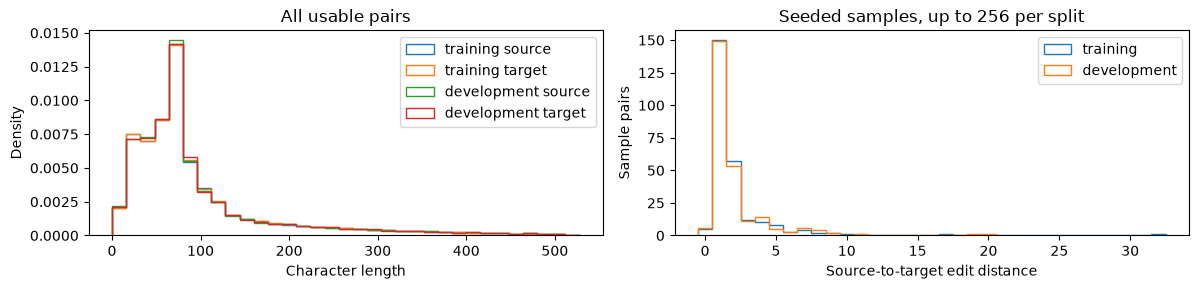

| Split | Edit-distance sample size | Mean | Median |
| --- | --- | --- | --- |
| training | 256 | 2.03 | 1.0 |
| development | 256 | 2.07 | 1.0 |

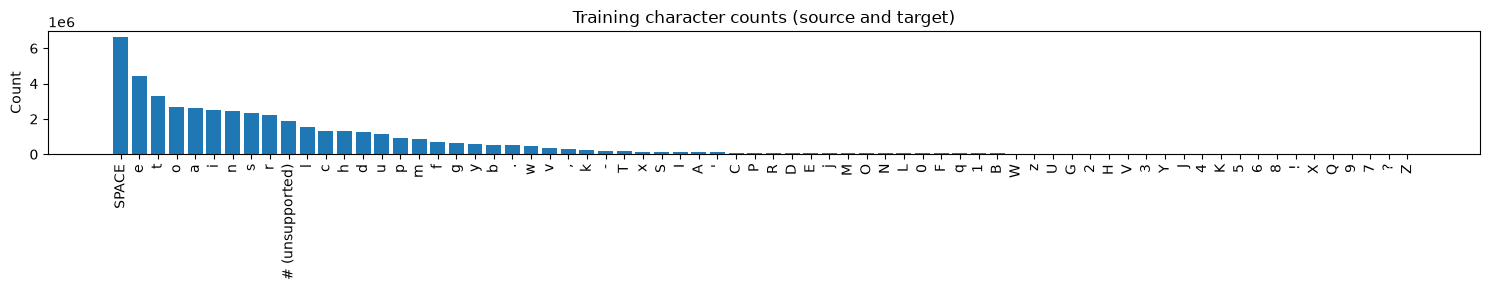

| Training index (after blank filtering) | Noisy input | Clean target | Edit distance |
| --- | --- | --- | --- |
| 23 | '# - IGPU property enable-cfl-backlight-fix turns patch on' | '# - IGPU property enable-cfl-backlight-fix turns patch on' | 0 |
| 0 | 'IN.User.authorize#function###' | 'IN.User.authorize#function## #' | 1 |
| 9611 | '# #' | '# #' | 0 |
| 311 | "##onFileUploadFinish###imageUploaded##event###. If ##src## is specified this event is fired when component gets a responce from the server, also in this case event has field #serverResponse# which contains object returned by the server. If ##src## is not specified it's fired immediately after an image#s# dropped into file-drop zone of choosed in file browser. So what you can do, is not specify ##src## to handle upload yourself, for exapmple send the image into firebase storage. To get file use #event.file#." | "##onFileUploadFinish###imageUploaded##event###. If ##url## is specified this event is fired when component gets a responce from the server, also in this case event has field #serverResponse# which contains object returned by the server. If ##url## is not specified it's fired immediately after an image#s# dropped into file-drop zone of choosed in file browser. So what you can do, is not specify ##url## to handle upload yourself, for exapmple send the image into firebase storage. To get file use #event.file#." | 6 |
| 50005 | '4. To filter by multiple attributes with the #AMD# operator#' | '4. To filter by multiple attributes with the #AND# operator#' | 1 |
| 123854 | "# Get all of the video's comment." | "# Get all of the video's comments." | 1 |
| 201218 | '#description## #Monitor openstack platform using the SignalFx collectd agent.#,' | '#description## #Monitor OpenStack platform using the SignalFx collectd agent.#,' | 2 |

7630

In [3]:
def sample_indices(size, count, seed=SEED):
    if size < 0 or count < 0:
        raise ValueError('Sample sizes must be nonnegative')
    return sorted(np.random.default_rng(seed).choice(size, min(count, size), replace=False).tolist())


exploration = {'split_audit': split_summary}
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
summary_rows, length_rows = [], []
for name, pairs, stats in [('training', train_pairs, train_stats), ('development', dev_pairs, dev_stats)]:
    lengths = np.array([[len(s), len(t)] for s, t in pairs])
    frequencies = Counter(c for pair in pairs for text in pair for c in text)
    marker_pairs = sum('#' in s or '#' in t for s, t in pairs)
    indices = sample_indices(len(pairs), 256)
    distances = edit_distances([pairs[i][0] for i in indices], [pairs[i][1] for i in indices])
    exploration[name] = dict(usable_pairs=len(pairs), paired_blanks_skipped=stats.get('paired_blanks_skipped', 0),
                             unchanged=stats['unchanged'], changed=len(pairs) - stats['unchanged'],
                             marker_pairs=marker_pairs, marker_characters=frequencies['#'],
                             total_characters=sum(frequencies.values()),
                             distance_sample_indices=indices, distance_sample_size=len(indices),
                             distance_mean=float(np.mean(distances)), distance_median=float(np.median(distances)))
    summary_rows.append([name, stats['rows'], len(pairs), stats.get('paired_blanks_skipped', 0),
                         f"{stats['unchanged'] / len(pairs):.2%}", f'{marker_pairs / len(pairs):.2%}',
                         f"{frequencies['#'] / sum(frequencies.values()):.2%}"])
    for column, label in enumerate(['source', 'target']):
        quantiles = np.quantile(lengths[:, column], [0, .25, .5, .75, .95, 1])
        length_rows.append([name, label] + [f'{v:.1f}' for v in quantiles])
        axes[0].hist(lengths[:, column], bins=np.arange(0, MAX_CHARS + 17, 16), histtype='step',
                     density=True, label=name + ' ' + label)
    axes[1].hist(distances, bins=np.arange(0, max(distances) + 2) - .5, histtype='step', label=name)
show_table(['Split', 'Raw rows', 'Usable', 'Blank pairs skipped', 'Unchanged', 'Pairs with #', '# share (both sides)'], summary_rows)
show_table(['Split', 'Side', 'Min', 'Q25', 'Median', 'Q75', 'Q95', 'Max'], length_rows)
axes[0].set(xlabel='Character length', ylabel='Density', title='All usable pairs')
axes[1].set(xlabel='Source-to-target edit distance', ylabel='Sample pairs', title='Seeded samples, up to 256 per split')
for ax in axes:
    ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'corpus_distributions.png', dpi=150)
plt.show()
show_table(['Split', 'Edit-distance sample size', 'Mean', 'Median'],
           [[name, data['distance_sample_size'], f"{data['distance_mean']:.2f}", data['distance_median']]
            for name, data in exploration.items() if name != 'split_audit'])

training_frequencies = Counter(c for pair in train_pairs for text in pair for c in text)
frequency_items = training_frequencies.most_common()
fig, ax = plt.subplots(figsize=(15, 3))
ax.bar(['SPACE' if c == SPACE else '# (unsupported)' if c == '#' else c for c, _ in frequency_items],
       [count for _, count in frequency_items])
ax.set(title='Training character counts (source and target)', ylabel='Count')
ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'character_frequencies.png', dpi=150)
plt.show()

example_indices = list(dict.fromkeys([
    next(i for i, (s, t) in enumerate(train_pairs) if s == t),
    next(i for i, (s, t) in enumerate(train_pairs) if s != t),
    min(range(len(train_pairs)), key=lambda i: max(map(len, train_pairs[i]))),
    max(range(len(train_pairs)), key=lambda i: max(map(len, train_pairs[i])))] + sample_indices(len(train_pairs), 3)))
show_table(['Training index (after blank filtering)', 'Noisy input', 'Clean target', 'Edit distance'],
           [[i, repr(display_content(train_pairs[i][0])), repr(display_content(train_pairs[i][1])),
             edit_distance(*train_pairs[i])] for i in example_indices])
(OUTPUT_DIR / 'exploration.json').write_text(json.dumps(exploration, indent=2), encoding='utf-8')


## 2. Encoder-decoder Transformer
The encoder reads the noisy sequence bidirectionally. Each decoder block has causal self-attention, encoder cross-attention, and a position-wise feed-forward network, with residual connections, layer normalization and dropout. Training uses teacher forcing: decoder input is `BOS + target`, and labels are `target + EOS`.

### Architecture rationale 
The GPU experiment uses four encoder and four decoder blocks, width 128, four attention heads and feed-forward width 512: a modest starting configuration for a small character vocabulary, not a tuned optimum. Each head has width 32. Dropout 0.1 regularizes residual updates; training/dev curves should be inspected for underfitting or overfitting before changing it. The 512-character content limit fixes positional capacity rather than truncating data. Separate BOS/EOS distinguish sequence boundaries from padding. Masking prevents future-target leakage and padding-dependent learning signals. The warmup/inverse-square-root schedule stabilizes early updates and decreases the learning rate later; best development loss selects an inference checkpoint, while autoregressive metrics test whether that checkpoint actually corrects text. The two-block `cpu` fallback is a separate reduced experiment, not the source of the reported GPU results.

Boolean masks exclude padding keys **and queries** and prevent access to future decoder tokens. Learned positional embeddings have capacity `MODEL_MAX_CHARS + 2` (514 in smoke/full mode, 130 in CPU mode: content characters plus two boundary tokens). Loss is the mean cross-entropy over non-padding tokens in each batch; epoch loss averages these batch losses. Token accuracy accumulates non-padding correct/total counts across the epoch. No padding contributes to either measure.

In [4]:
def attention_masks(source, target):
    src_ok, tgt_ok = tf.not_equal(source, PAD), tf.not_equal(target, PAD)
    src_mask = src_ok[:, :, None] & src_ok[:, None, :]
    length = tf.shape(target)[1]
    causal = tf.range(length)[:, None] >= tf.range(length)[None, :]
    tgt_mask = tgt_ok[:, :, None] & tgt_ok[:, None, :] & causal[None, :, :]
    cross_mask = tgt_ok[:, :, None] & src_ok[:, None, :]
    return src_mask, tgt_mask, cross_mask


class TokenPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, vocab_size, d_model, capacity):
        super().__init__()
        self.tokens = tf.keras.layers.Embedding(vocab_size, d_model)
        self.positions = tf.keras.layers.Embedding(capacity, d_model)
        self.scale = math.sqrt(d_model)

    def call(self, ids):
        return self.tokens(ids) * self.scale + self.positions(tf.range(tf.shape(ids)[1]))


class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout):
        super().__init__()
        self.attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.ff = tf.keras.Sequential([tf.keras.layers.Dense(ff_dim, activation='relu'), tf.keras.layers.Dense(d_model)])
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = tf.keras.layers.Dropout(dropout)
        self.drop2 = tf.keras.layers.Dropout(dropout)

    def call(self, x, attention_mask, training=False):
        update = self.attention(x, x, attention_mask=attention_mask, training=training)
        x = self.norm1(x + self.drop1(update, training=training))
        return self.norm2(x + self.drop2(self.ff(x), training=training))


class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout):
        super().__init__()
        self.self_attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.cross_attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.ff = tf.keras.Sequential([tf.keras.layers.Dense(ff_dim, activation='relu'), tf.keras.layers.Dense(d_model)])
        self.norms = [tf.keras.layers.LayerNormalization(epsilon=1e-6) for _ in range(3)]
        self.drops = [tf.keras.layers.Dropout(dropout) for _ in range(3)]

    def call(self, x, encoded, self_mask, cross_mask, training=False):
        update = self.self_attention(x, x, attention_mask=self_mask, training=training)
        x = self.norms[0](x + self.drops[0](update, training=training))
        update = self.cross_attention(x, encoded, attention_mask=cross_mask, training=training)
        x = self.norms[1](x + self.drops[1](update, training=training))
        return self.norms[2](x + self.drops[2](self.ff(x), training=training))


class SpellTransformer(tf.keras.Model):
    def __init__(self, vocab_size, max_chars, d_model, num_heads, ff_dim, num_layers, dropout):
        super().__init__()
        if d_model % num_heads:
            raise ValueError('d_model must be divisible by num_heads')
        self.src_embedding = TokenPositionEmbedding(vocab_size, d_model, max_chars + 2)
        self.tgt_embedding = TokenPositionEmbedding(vocab_size, d_model, max_chars + 2)
        self.src_dropout = tf.keras.layers.Dropout(dropout)
        self.tgt_dropout = tf.keras.layers.Dropout(dropout)
        args = (d_model, num_heads, ff_dim, dropout)
        self.encoders = [EncoderBlock(*args) for _ in range(num_layers)]
        self.decoders = [DecoderBlock(*args) for _ in range(num_layers)]
        self.projection = tf.keras.layers.Dense(vocab_size, dtype='float32')

    def encode(self, source, training=False):
        src_ok = tf.not_equal(source, PAD)
        src_mask = src_ok[:, :, None] & src_ok[:, None, :]
        encoded = self.src_dropout(self.src_embedding(source), training=training)
        for block in self.encoders:
            encoded = block(encoded, attention_mask=src_mask, training=training)
        return encoded

    def decode(self, source, encoded, target, training=False):
        _, tgt_mask, cross_mask = attention_masks(source, target)
        decoded = self.tgt_dropout(self.tgt_embedding(target), training=training)
        for block in self.decoders:
            decoded = block(decoded, encoded, self_mask=tgt_mask, cross_mask=cross_mask, training=training)
        return self.projection(decoded)

    def call(self, inputs, training=False):
        source, target = inputs
        return self.decode(source, self.encode(source, training=training), target, training=training)


def masked_loss(labels, logits):
    per_token = tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
    mask = tf.cast(labels != PAD, per_token.dtype)
    return tf.math.divide_no_nan(tf.reduce_sum(per_token * mask), tf.reduce_sum(mask))


class MaskedAccuracy(tf.keras.metrics.SparseCategoricalAccuracy):
    def __init__(self, name='masked_accuracy', **kwargs):
        super().__init__(name=name, **kwargs)

    def update_state(self, labels, logits, sample_weight=None):
        valid = tf.cast(labels != PAD, self.dtype)
        if sample_weight is not None:
            valid *= tf.cast(sample_weight, self.dtype)
        super().update_state(tf.reshape(labels, [-1]), tf.reshape(logits, [-1, tf.shape(logits)[-1]]),
                             sample_weight=tf.reshape(valid, [-1]))


model = SpellTransformer(**CONFIG)
batch_inputs, batch_labels = next(iter(train_ds))
batch_logits = model(batch_inputs)
assert batch_logits.shape[:2] == batch_labels.shape
model.summary()
show_table(['Mode', 'Train pairs', 'Validation pairs', 'Blocks per side', 'Width', 'Heads', 'FF width', 'Dropout', 'Parameters', 'Batch', 'Max epochs'],
           [[MODE, len(training_pairs), len(validation_pairs), CONFIG['num_layers'], CONFIG['d_model'],
             CONFIG['num_heads'], CONFIG['ff_dim'], CONFIG['dropout'], model.count_params(), BATCH_SIZE, EPOCHS]])


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

Model: "spell_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_position_embedding        │ ?                      │        75,136 │
│ (TokenPositionEmbedding)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_position_embedding_1      │ ?                      │        75,136 │
│ (TokenPositionEmbedding)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block (EncoderBlock)    │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_1 (EncoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_2 (EncoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_3 (EncoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block (DecoderBlock)    │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_1 (DecoderBlock)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_2 (DecoderBlock)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_3 (DecoderBlock)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (32, 71, 73)           │         9,417 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,011,081 (7.67 MB)

 Trainable params: 2,011,081 (7.67 MB)

 Non-trainable params: 0 (0.00 B)

| Mode | Train pairs | Validation pairs | Blocks per side | Width | Heads | FF width | Dropout | Parameters | Batch | Max epochs |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| full | 242304 | 2000 | 4 | 128 | 4 | 512 | 0.1 | 2011081 | 32 | 30 |

## 3. Training and portable checkpoints
GPU training uses Adam with the Transformer schedule `d_model^-0.5 * min(step^-0.5, step * warmup^-1.5)` and gradient clipping. Full GPU mode uses batches of 32, 4,000 warmup steps, up to 30 epochs and patience five. The `cpu` fallback and smoke test retain their separate reduced settings. Best development loss selects the weights, not the last epoch.

The default `REUSE_TRAINED = True` reuses a matching checkpoint; set it to `False` for fresh training. Reuse checks the model, vocabulary, SHA-256 hashes, source-group split indices, framework versions, precision and statistical run settings. Earlier bundles without a precision field used float32 and remain compatible. The tensor input pipeline and steps-per-execution are runtime optimizations, not new checkpoint-selection criteria. Fresh full-mode training runs 32 optimizer steps per Keras execution, reducing Python dispatch overhead; progress logging handles callbacks that cross a reporting threshold. Historical CPU outputs predate this split strategy and are not the GPU experiment.

The intact completed float32 GPU checkpoint is reused from `outputs/optimized-float32`. Fresh float32 GPU training defaults to `outputs/full-retrain`; new bfloat16 GPU experiments default to `outputs/full-mixed_bfloat16`. Smoke tests and the explicit reduced fallback have separate directories. `SPELLCHECK_OUTPUT_DIR` overrides the destination. Fresh training replaces that destination's checkpoint and metadata, so choose a new directory for a separate experiment. Reuse never silently falls back to training. Saved weights are accompanied by vocabulary, architecture, normalization and training metadata. `load_bundle` constructs a fresh model and validates the metadata; it does not require the training files. The notebook's model class definitions are required for reload. Optimizer state is not restored by this inference bundle.

### Full GPU run and evidence checklist
1. Select a compatible TensorFlow GPU kernel and place all four tokenized files in `gtc`. Verify that the setup cell lists the intended GPU; CPU execution is supported but is not evidence of GPU training.
2. Use the default `MODE = 'full'`, choose a batch size that fits memory, then rerun all cells. Full mode uses all 242,304 usable training pairs, four encoder/decoder blocks, and up to 30 epochs. The supplied 12,752 development rows are audited, training-source overlaps excluded, and remaining noisy-source groups divided into checkpoint selection and evaluation. Smoke mode uses 32 training pairs, at least eight validation rows, one block per side and two epochs; the configurations are not interchangeable.
3. Retain `best.weights.h5`, `metadata.json`, `history.json`, the curves, aggregate evaluation, and per-example predictions from the printed `OUTPUT_DIR`. Check that metadata says `full` and inspect the actual completed epoch count rather than assuming all epochs ran.
4. Evaluate the selected checkpoint autoregressively on **all eligible held-out development rows**; inspect EOS failures, the copy baseline, changed-input corrections and overcorrection, not just teacher-forced accuracy. Batched inference caches encoder states but recomputes decoder states per character, so this is substantially more expensive than teacher-forced validation.
5. Save the executed notebook after the real run. Only those actual outputs can support final performance interpretation. Local smoke verification does not fulfill full training or prove correction quality.

### Evaluate a saved bundle without retraining
In a fresh kernel, run setup with the matching mode/output directory, data/helper definitions, and model definitions (exploration is optional). **Skip the training cell** containing `model.fit` and all metadata/history writes. Run the separate reload/curves cell below, then prediction/evaluation and interpretation. The curves are read from the saved history. Confirm the loaded metadata's mode/configuration before interpreting results; do not overwrite a full bundle with a smoke run. The final implementation-validation cell compares against the just-trained model, so run it only in a complete training/smoke workflow, not in this evaluation-only path.

Only the checkpoint-selection source groups choose weights. Evaluation source groups are disjoint from both training and checkpoint selection; they remain a held-out partition of the supplied development corpus, not an externally collected test set. Repeatedly tuning on these evaluation results would compromise that holdout. The GitHub/code-heavy domain may not generalize to ordinary prose.

In [5]:
class TransformerSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps):
        super().__init__()
        self.d_model, self.warmup_steps = d_model, warmup_steps

    def __call__(self, step):
        step = tf.cast(step + 1, tf.float32)
        return self.d_model ** -0.5 * tf.minimum(tf.math.rsqrt(step), step * self.warmup_steps ** -1.5)

    def get_config(self):
        return dict(d_model=self.d_model, warmup_steps=self.warmup_steps)


class ProgressLog(tf.keras.callbacks.Callback):
    """Logs progress even when Keras executes several batches per callback."""

    def __init__(self, path, every=250):
        super().__init__()
        self.path, self.every, self.epoch, self.started = path, every, 0, None

    def _write(self, line):
        with self.path.open('a', encoding='utf-8') as log:
            log.write(f'{time.perf_counter() - self.started:7.0f}s  {line}\n')

    def on_train_begin(self, logs=None):
        self.started = time.perf_counter()
        self.path.write_text('', encoding='utf-8')

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch, self.next_log = epoch + 1, self.every

    def on_train_batch_end(self, batch, logs=None):
        if batch + 1 >= self.next_log:
            self._write(f"epoch {self.epoch} batch {batch + 1} loss {float(logs['loss']):.4f}")
            self.next_log = ((batch + 1) // self.every + 1) * self.every

    def on_epoch_end(self, epoch, logs=None):
        self._write(f'epoch {epoch + 1} done: ' + ', '.join(f'{k}={float(v):.4f}' for k, v in logs.items()))


weights_path, metadata_path, history_path = (OUTPUT_DIR / name for name in
                                             ('best.weights.h5', 'metadata.json', 'history.json'))
run_signature = dict(mode=MODE, seed=SEED, train_pairs=len(training_pairs), validation_pairs=len(validation_pairs),
                     warmup_steps=WARMUP, batch_size=BATCH_SIZE, max_epochs=EPOCHS, patience=PATIENCE,
                     validation_indices=validation_indices, evaluation_pool_indices=evaluation_pool_indices,
                     split_strategy=split_summary['strategy'], dataset_sha256=dataset_sha256,
                     tensorflow_version=tf.__version__, keras_version=tf.keras.__version__, precision_policy=PRECISION_POLICY)
previous = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else None
if previous is not None:
    previous['training'].setdefault('precision_policy', 'float32')
reuse = (REUSE_TRAINED and previous is not None and weights_path.exists() and history_path.exists()
         and previous.get('model_config') == CONFIG and previous.get('tokens') == id_to_token
         and all(previous['training'].get(key) == value for key, value in run_signature.items()))
if REUSE_TRAINED and not reuse:
    reasons = [f'missing {path.name}' for path in (weights_path, metadata_path, history_path) if not path.is_file()]
    if previous is not None:
        reasons += [key for key, value in run_signature.items() if previous['training'].get(key) != value]
        reasons += [key for key, value in dict(model_config=CONFIG, tokens=id_to_token).items() if previous.get(key) != value]
    raise RuntimeError(f"Cannot reuse checkpoint in {OUTPUT_DIR}: {', '.join(reasons)}. "
                       'No training was started. Restore the matching bundle, or explicitly set REUSE_TRAINED = False '
                       'and choose a separate output directory for a new experiment.')
if reuse:
    model.load_weights(weights_path)
    history_values = json.loads(history_path.read_text(encoding='utf-8'))
    print(f"Reusing saved {MODE} checkpoint: {previous['training']['epochs_completed']} epochs, "
          f"{previous['training']['training_seconds'] / 60:.1f} min of training. Set REUSE_TRAINED = False to retrain.")
else:
    model.compile(optimizer=tf.keras.optimizers.Adam(TransformerSchedule(CONFIG['d_model'], WARMUP),
                                                   beta_1=0.9, beta_2=0.98, epsilon=1e-9, global_clipnorm=1.0),
                  loss=masked_loss, metrics=[MaskedAccuracy()], jit_compile=False, steps_per_execution=STEPS_PER_EXECUTION)
    callbacks = [tf.keras.callbacks.TerminateOnNaN(),
                 tf.keras.callbacks.ModelCheckpoint(str(weights_path), monitor='val_loss', save_best_only=True,
                                                    save_weights_only=True),
                 tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                 ProgressLog(OUTPUT_DIR / 'training_progress.log')]
    started = time.perf_counter()
    history = model.fit(train_ds, validation_data=dev_ds, epochs=EPOCHS, callbacks=callbacks, shuffle=False, verbose=2)
    training_seconds = time.perf_counter() - started
    history_values = history.history
    if not all(np.isfinite(v) for values in history_values.values() for v in values):
        raise FloatingPointError('Non-finite training metric; checkpoint must not be used')
    model.load_weights(weights_path)
    metadata = dict(format_version=1, model_config=CONFIG, tokens=id_to_token,
                    normalization=dict(space_token=SPACE, unsupported_token='#', max_chars=MODEL_MAX_CHARS),
                    training=dict(run_signature, available_train_pairs=len(train_pairs),
                                  available_dev_pairs=len(dev_pairs), parameter_count=model.count_params(),
                                  checkpoint_monitor='val_loss', tensorflow_version=tf.__version__,
                                  keras_version=tf.keras.__version__, epochs_completed=len(history_values['loss']),
                                  best_validation_loss=min(history_values['val_loss']),
                                  training_seconds=round(training_seconds, 1), split_summary=split_summary,
                                  steps_per_execution=STEPS_PER_EXECUTION, input_pipeline='tensor-slices-v1',
                                  gpu_devices=[tf.config.experimental.get_device_details(gpu).get('device_name', gpu.name)
                                               for gpu in gpu_devices]))
    metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=True), encoding='utf-8')
    history_path.write_text(json.dumps(history_values, indent=2), encoding='utf-8')
    print(f'Training finished in {training_seconds / 60:.1f} min.')


Reusing saved full checkpoint: 30 epochs, 492.6 min of training. Set REUSE_TRAINED = False to retrain.


/home/nizare/GitHub/dl-ai570/.venv/lib/python3.12/site-packages/keras/src/ops/nn.py:959: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Loaded checkpoint: {'mode': 'full', 'seed': 574, 'train_pairs': 242304, 'validation_pairs': 2000, 'warmup_steps': 4000, 'batch_size': 32, 'max_epochs': 30, 'patience': 5, 'split_strategy': 'noisy-source-groups-v1', 'dataset_sha256': {'train.tok.fr.txt': '814466814b7fe43810add32767592d6331dc06e4a9237d73617be4ab598a6633', 'train.tok.en.txt': '2f3b3d1d800bcebd512a8cb09ad43b46961e4ba223345092a93bdb6b56f66d11', 'dev.tok.fr.txt': 'e9e4136572f4c7685379a88114eaf5dc00f6991164eb2ad7a2f16899281036f8', 'dev.tok.en.txt': '9e9bb44fd157239d770e5ad20ce1557783308d9832defde519e232fdc349aed3'}, 'tensorflow_version': '2.17.0', 'keras_version': '3.15.0', 'available_train_pairs': 242304, 'available_dev_pairs': 12752, 'parameter_count': 2011081, 'checkpoint_monitor': 'val_loss', 'epochs_completed': 30, 'best_validation_loss': 0.06742515414953232, 'training_seconds': 29553.8, 'split_summary': {'strategy': 'noisy-source-groups-v1', 'development_rows': 12752, 'duplicate_pairs': 425, 'duplicate_source_rows': 427

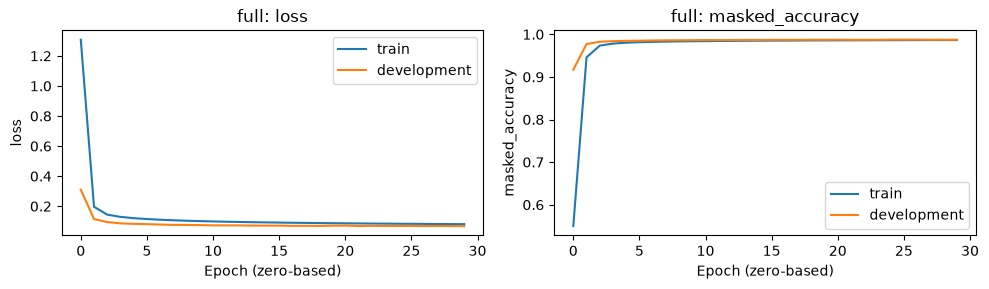

In [6]:
def load_bundle(directory):
    directory = Path(directory)
    saved = json.loads((directory / 'metadata.json').read_text(encoding='utf-8'))
    tokens = saved['tokens']
    normalization = saved['normalization']
    if saved['format_version'] != 1 or tokens[:3] != ['<pad>', '<bos>', '<eos>']:
        raise ValueError('Unsupported bundle format or special-token IDs')
    if len(set(tokens)) != len(tokens) or any(len(t) != 1 for t in tokens[3:]):
        raise ValueError('Invalid saved character vocabulary')
    if normalization != dict(space_token=SPACE, unsupported_token='#', max_chars=MODEL_MAX_CHARS):
        raise ValueError('Bundle normalization is incompatible with this notebook')
    if not {SPACE, '#'} <= set(tokens) or saved['model_config']['vocab_size'] != len(tokens):
        raise ValueError('Bundle vocabulary/configuration mismatch')
    if saved['model_config']['max_chars'] != MODEL_MAX_CHARS:
        raise ValueError('Bundle length limit is incompatible with this notebook')
    if saved['training'].get('precision_policy', 'float32') != PRECISION_POLICY:
        raise ValueError('Bundle precision differs from PRECISION_POLICY; select its matching experiment')
    restored = SpellTransformer(**saved['model_config'])
    restored((tf.constant([[BOS, EOS]]), tf.constant([[BOS]])))
    restored.load_weights(directory / 'best.weights.h5')
    return restored, saved


inference_model, saved_metadata = load_bundle(OUTPUT_DIR)
print('Loaded checkpoint:', {k: v for k, v in saved_metadata['training'].items() if not k.endswith('_indices')})
saved_history = json.loads((OUTPUT_DIR / 'history.json').read_text(encoding='utf-8'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, name in zip(axes, ['loss', 'masked_accuracy']):
    ax.plot(saved_history[name], label='train')
    ax.plot(saved_history['val_' + name], label='development')
    ax.set(xlabel='Epoch (zero-based)', ylabel=name, title=MODE + ': ' + name)
    ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
plt.show()


## 4. Autoregressive correction and evaluation
Greedy decoding starts at BOS, excludes PAD/BOS from generated content, and stops at EOS. Missing EOS raises `GenerationError`; it is never disguised as a successful truncated correction. Generation for an input of length *n* may produce at most `min(limit, n + 50)` characters (the corpus never adds more than 43 characters to a source). Smoke mode deliberately caps generated content at 32 characters to bound validation work; CPU mode allows 128 and full mode 512. The decoder makes one additional decision to allow EOS immediately after the last permitted character.

Evaluation uses normalized corpus characters (displaying the whitespace marker as a space). Exact match counts failed decoding as incorrect and reports the failure count/rate. Corpus character error rate (sum of Levenshtein distances divided by sum of reference lengths) is reported only if every example terminates; otherwise it is `None`, not a biased success-only score. A second, always-defined CER counts every failed decode as an empty output, so failures are fully penalized rather than ignored. Unchanged preservation and changed-example exact match expose overcorrection and copying. An absent subgroup is reported as `None` with its count of zero.

All modes evaluate only the held-out noisy-source groups, excluding training-source overlaps. Smoke evaluation selects up to two short changed and two short unchanged held-out rows; this stratified workflow check is **not** a quality estimate. CPU evaluation samples up to 4,000 eligible rows within 128 characters. Full evaluation uses every eligible held-out row, including long examples. Duplicate held-out rows retain their corpus frequency; none of their noisy inputs occur in training or checkpoint selection.

Evaluation decodes inputs in length-sorted batches with the encoder computed once per batch. This is an efficiency change only: greedy choices, stopping rules and limits are identical to single-input decoding, and a check below compares both paths on real development inputs. Saved indices refer to the validated split after blank filtering, not original file line numbers. Per-example failures retain the error message and a null prediction; they are never replaced with copied inputs.

In [7]:
class GenerationError(RuntimeError):
    pass


def greedy_decode(predictor, source_ids, vocab_size, max_chars=MODEL_MAX_CHARS):
    result, error = batch_greedy_decode(predictor, [source_ids], vocab_size, [max_chars])[0]
    if error:
        raise GenerationError(error)
    return result


def batch_greedy_decode(predictor, source_batch, vocab_size, limits):
    """Greedy-decode several inputs at once; returns (token_ids, None) or (None, error) per input."""
    if not source_batch or len(source_batch) != len(limits):
        raise ValueError('Batch decoding requires aligned, nonempty sources and limits')
    if any(not 1 <= limit <= MODEL_MAX_CHARS for limit in limits):
        raise ValueError(f'Decode limits must be between 1 and {MODEL_MAX_CHARS}')
    rows, width = len(source_batch), max(map(len, source_batch))
    source = tf.constant([ids + [PAD] * (width - len(ids)) for ids in source_batch], dtype=tf.int32)
    generated = np.full((rows, max(limits) + 1), PAD, dtype=np.int32)
    generated[:, 0] = BOS
    active, limits = np.ones(rows, dtype=bool), np.asarray(limits)
    results = [None] * rows
    for step in range(max(limits) + 1):
        logits = predictor((source, tf.constant(generated[:, :step + 1])), training=False)
        scores = np.array(logits[:, -1, :], dtype=np.float64, copy=True)
        if scores.shape != (rows, vocab_size):
            raise GenerationError('Invalid decoder logits shape')
        finite = np.isfinite(scores).all(axis=1)
        scores[:, [PAD, BOS]] = -np.inf
        next_ids = scores.argmax(axis=1)
        for i in np.flatnonzero(active & (~finite | (next_ids == EOS) | (step == limits))):
            error = ('Invalid or non-finite decoder logits' if not finite[i] else
                     None if next_ids[i] == EOS else f'Decoder did not emit EOS within {limits[i]} content characters')
            results[i], active[i] = (None if error else generated[i, 1:step + 1].tolist(), error), False
        if not active.any():
            break
        generated[active, step + 1] = next_ids[active]
    return results


class CompiledPredictor:
    """Compiled inference that encodes each source batch once and reruns only the decoder per step."""

    def __init__(self, model):
        @tf.function(reduce_retracing=True)
        def encode(source):
            return model.encode(source, training=False)

        @tf.function(reduce_retracing=True)
        def decode_last(source, encoded, target):
            return model.decode(source, encoded, target, training=False)[:, -1:, :]

        self._encode, self._decode_last = encode, decode_last
        self._source, self._encoded = None, None

    def __call__(self, inputs, training=False):
        source, target = inputs
        if source is not self._source:
            self._source, self._encoded = source, self._encode(source)
        return self._decode_last(source, self._encoded, target)


class SpellChecker:
    def __init__(self, predictor, bundle_metadata, max_decode_chars=MODEL_MAX_CHARS, decode_margin=DECODE_MARGIN):
        self.predictor = predictor
        self.tokens = bundle_metadata['tokens']
        self.lookup = {token: i for i, token in enumerate(self.tokens)}
        self.max_decode_chars = max_decode_chars
        self.decode_margin = decode_margin

    def _prepare(self, text):
        normalized = normalize_raw(text, self.lookup)
        limit = min(self.max_decode_chars, len(normalized) + self.decode_margin)
        return [BOS] + [self.lookup[c] for c in normalized] + [EOS], limit

    def _result(self, text, result_ids):
        corrected = ''.join(self.tokens[i] for i in result_ids).replace(SPACE, ' ')
        return dict(corrected_text=corrected, changed=corrected != text)

    def correct(self, text):
        source_ids, limit = self._prepare(text)
        if text == '':
            return dict(corrected_text='', changed=False)
        return self._result(text, greedy_decode(self.predictor, source_ids, len(self.tokens), limit))

    def correct_batch(self, texts, batch_size=64, progress_every=None):
        """Correct many texts; returns (result, None) or (None, generation_error) per text, in input order."""
        prepared = [self._prepare(text) for text in texts]
        outcomes = [(dict(corrected_text='', changed=False), None) if text == '' else None for text in texts]
        pending = sorted((i for i, text in enumerate(texts) if text != ''), key=lambda i: len(prepared[i][0]))
        started = time.perf_counter()
        for batch_number, start in enumerate(range(0, len(pending), batch_size), 1):
            chunk = pending[start:start + batch_size]
            decoded = batch_greedy_decode(self.predictor, [prepared[i][0] for i in chunk], len(self.tokens),
                                          [prepared[i][1] for i in chunk])
            for i, (result_ids, error) in zip(chunk, decoded):
                outcomes[i] = (None, error) if error else (self._result(texts[i], result_ids), None)
            if progress_every and (batch_number % progress_every == 0 or start + batch_size >= len(pending)):
                print(f'Decoded {min(start + batch_size, len(pending))}/{len(pending)} inputs '
                      f'in {time.perf_counter() - started:.0f}s')
        return outcomes


def correction_metrics(sources, references, predictions):
    if not sources or not len(sources) == len(references) == len(predictions):
        raise ValueError('Metrics require nonempty, aligned sources/references/predictions')
    unchanged = [i for i, (s, r) in enumerate(zip(sources, references)) if s == r]
    changed = [i for i, (s, r) in enumerate(zip(sources, references)) if s != r]
    exact = [p == r for p, r in zip(predictions, references)]
    failures = sum(p is None for p in predictions)
    reference_chars = sum(map(len, references))
    conservative_cer = (sum(edit_distances([p if p is not None else '' for p in predictions], references))
                        / reference_chars if reference_chars else None)
    cer = conservative_cer if not failures else None
    return dict(examples=len(sources), unchanged_examples=len(unchanged), changed_examples=len(changed),
                reference_characters=reference_chars, decode_failures=failures,
                decode_failure_rate=failures / len(sources), exact_match=sum(exact) / len(exact),
                character_error_rate=cer, character_error_rate_failures_as_empty=conservative_cer,
                unchanged_preservation=sum(exact[i] for i in unchanged) / len(unchanged) if unchanged else None,
                changed_exact_match=sum(exact[i] for i in changed) / len(changed) if changed else None)


def evaluation_indices(pairs, mode, pool_indices):
    if not pool_indices or len(set(pool_indices)) != len(pool_indices):
        raise ValueError('Evaluation pool must be nonempty with unique indices')
    if any(i < 0 or i >= len(pairs) for i in pool_indices):
        raise ValueError('Evaluation pool index outside development corpus')
    if mode == 'full':
        return sorted(pool_indices)
    if mode == 'cpu':
        count = min(CPU_EVALUATION_PAIRS, len(pool_indices))
        return sorted(np.random.default_rng(SEED + 1).choice(pool_indices, count, replace=False).tolist())
    if mode != 'smoke':
        raise ValueError('Evaluation mode must be smoke, cpu or full')
    selected = []
    for unchanged in [False, True]:
        group = [i for i in sorted(pool_indices) if (pairs[i][0] == pairs[i][1]) == unchanged
                 and max(map(len, pairs[i])) <= 80]
        selected.extend(group[:2])
    if not selected:
        raise ValueError('No short examples available for smoke evaluation')
    return sorted(selected)


evaluation_mode = saved_metadata['training']['mode']
if evaluation_mode != MODE:
    raise ValueError('Loaded bundle mode differs from MODE; select the matching bundle before evaluating')
for key, expected in [('dataset_sha256', dataset_sha256), ('validation_indices', validation_indices),
                      ('evaluation_pool_indices', evaluation_pool_indices), ('split_strategy', split_summary['strategy'])]:
    if saved_metadata['training'].get(key) != expected:
        raise ValueError(f'Checkpoint {key} does not match this dataset/split; retrain before evaluating')
checker = SpellChecker(CompiledPredictor(inference_model), saved_metadata, max_decode_chars=DECODE_LIMIT)
selected_indices = evaluation_indices(dev_pairs, evaluation_mode, evaluation_pool_indices)
evaluation_pairs = [dev_pairs[i] for i in selected_indices]
sources = [display_content(s) for s, _ in evaluation_pairs]
references = [display_content(t) for _, t in evaluation_pairs]
started = time.perf_counter()
outcomes = checker.correct_batch(sources, batch_size=64, progress_every=20)
evaluation_seconds = time.perf_counter() - started
prediction_distances = edit_distances([result['corrected_text'] if result is not None else '' for result, _ in outcomes], references)
predictions, prediction_records = [], []
for index, (source, reference, (result, error_message), distance) in enumerate(zip(sources, references, outcomes, prediction_distances)):
    prediction = None if result is None else result['corrected_text']
    predictions.append(prediction)
    prediction_records.append(dict(development_index=selected_indices[index], source=source, reference=reference,
                                   prediction=prediction, generation_error=error_message,
                                   exact_match=prediction == reference, unchanged_input=source == reference,
                                   edit_distance=distance if prediction is not None else None))
failed_records = [record for record in prediction_records if record['generation_error']]
for record in failed_records[:5]:
    print(f"Development index {record['development_index']}: {record['generation_error']}")
if len(failed_records) > 5:
    print(f'... and {len(failed_records) - 5} more decoding failures')
expected_count = len(evaluation_pool_indices) if evaluation_mode == 'full' else len(selected_indices)
assert len(prediction_records) == expected_count
split_labels = dict(smoke='stratified source-disjoint development smoke subset',
                    cpu=f'seeded sample of source-disjoint held-out development pairs up to {MODEL_MAX_CHARS} characters',
                    full='all eligible source-disjoint held-out development pairs')
selection_labels = dict(smoke='up to two short examples per subgroup',
                        cpu=f'seeded sample of up to {CPU_EVALUATION_PAIRS} eligible held-out pairs',
                        full='all eligible held-out rows, excluding checkpoint-selection and training-source groups')
evaluation = dict(mode=evaluation_mode, split=split_labels[evaluation_mode],
                  available_development_examples=len(dev_pairs), expected_evaluated_examples=expected_count,
                  decode_limit=DECODE_LIMIT, decode_margin=DECODE_MARGIN, selection=selection_labels[evaluation_mode],
                  held_out_from_checkpoint_selection=True, source_disjoint_from_training=True,
                  split_summary=split_summary, dataset_sha256=dataset_sha256,
                  evaluation_seconds=round(evaluation_seconds, 1),
                  checkpoint_best_validation_loss=saved_metadata['training']['best_validation_loss'],
                  model=correction_metrics(sources, references, predictions),
                  copy_baseline=correction_metrics(sources, references, sources))
print(json.dumps(evaluation, indent=2))
(OUTPUT_DIR / 'evaluation.json').write_text(json.dumps(evaluation, indent=2), encoding='utf-8')
with (OUTPUT_DIR / 'predictions.jsonl').open('w', encoding='utf-8') as output:
    for record in prediction_records:
        output.write(json.dumps(record, ensure_ascii=True) + '\n')
for example in ['Ths is a smple sentnce.', 'I recieve teh files tomorow.', 'This is already correct.', '']:
    try:
        print(repr(example), '->', checker.correct(example))
    except GenerationError as error:
        print(repr(example), '-> GENERATION FAILED:', error)


/home/nizare/GitHub/dl-ai570/.venv/lib/python3.12/site-packages/keras/src/ops/nn.py:959: UserWarning: You are using a softmax over axis 3 of a tensor of shape (64, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Decoded 1280/5659 inputs in 9s
Decoded 2560/5659 inputs in 24s
Decoded 3840/5659 inputs in 44s
Decoded 5120/5659 inputs in 91s
Decoded 5659/5659 inputs in 237s
{
  "mode": "full",
  "split": "all eligible source-disjoint held-out development pairs",
  "available_development_examples": 12752,
  "expected_evaluated_examples": 5659,
  "decode_limit": 512,
  "decode_margin": 50,
  "selection": "all eligible held-out rows, excluding checkpoint-selection and training-source groups",
  "held_out_from_checkpoint_selection": true,
  "source_disjoint_from_training": true,
  "split_summary": {
    "strategy": "noisy-source-groups-v1",
    "development_rows": 12752,
    "duplicate_pairs": 425,
    "duplicate_source_rows": 427,
    "excluded_too_long": 0,
    "excluded_training_source_rows": 5093,
    "eligible_rows": 7659,
    "eligible_source_groups": 7614,
    "validation_rows": 2000,
    "held_out_rows": 5659
  },
  "dataset_sha256": {
    "train.tok.fr.txt": "814466814b7fe43810add32767592d6331

## Evaluation and interpretation
All scores and examples below come from the current run. Differences are **model minus copy baseline**, in absolute metric units, not relative improvement percentages. Higher exact match/preservation is better; lower CER/failure rate is better. A missing value is `N/A`, not zero. The example groups are descriptive output categories, not linguistic error diagnoses, and show at most three examples each in development-index order.

A successful correction exactly matches a changed reference. A missed/incorrect correction is a terminated, nonexact output for a changed reference. An overcorrection is a terminated output that alters an already-correct input. Failed decoding is listed separately, never counted as successful preservation. These are observed outcomes; attributing their causes requires further experiments.

In [8]:
def metric_delta(model_score, baseline_score):
    return None if model_score is None or baseline_score is None else model_score - baseline_score


def result_category(record):
    if record['prediction'] is None:
        return 'Decoding failures'
    if record['unchanged_input']:
        return 'Unchanged inputs preserved' if record['exact_match'] else 'Overcorrections'
    return 'Successful corrections' if record['exact_match'] else 'Missed/incorrect corrections'


def interpret_results(result):
    measured, baseline = result['model'], result['copy_baseline']
    statements = [f"Evaluated {measured['examples']} of {result['available_development_examples']} development pairs ({result['split']})."]
    if result['mode'] == 'smoke':
        statements.append('SMOKE ONLY: this subset and reduced model do not establish full-training correction quality.')
    elif result['mode'] == 'cpu':
        statements.append(f'Reduced CPU experiment: trained on pairs up to {MODEL_MAX_CHARS} characters and evaluated on '
                          'development pairs held out from checkpoint selection; results do not cover longer inputs '
                          'or the larger full-mode model.')
    else:
        statements.append('Full-mode results describe this checkpoint on source-disjoint held-out development groups, not an external test corpus.')
    delta = metric_delta(measured['exact_match'], baseline['exact_match'])
    if delta > 0:
        statements.append(f'Observed exact match exceeds copying by {delta:.4f} absolute units on this evaluated set.')
    elif delta < 0:
        statements.append(f'Observed exact match is below copying by {-delta:.4f} absolute units on this evaluated set.')
    else:
        statements.append('Observed exact match does not exceed copying; both scores are equal.')
    statements.append(f"Decoding failed for {measured['decode_failures']}/{measured['examples']} inputs ({measured['decode_failure_rate']:.3%}).")
    if measured['character_error_rate'] is None:
        statements.append('Overall model CER is unavailable; no success-only CER is substituted.')
        if measured.get('character_error_rate_failures_as_empty') is not None:
            statements.append(f"Counting each failed decode as an empty output (fully penalized), model CER is "
                              f"{measured['character_error_rate_failures_as_empty']:.4f} versus "
                              f"{baseline['character_error_rate_failures_as_empty']:.4f} for copying.")
    else:
        statements.append(f"Model CER is {measured['character_error_rate']:.4f}; copy CER is {baseline['character_error_rate']:.4f}.")
    if measured['unchanged_examples']:
        statements.append(f"Preserved {measured['unchanged_preservation']:.1%} of {measured['unchanged_examples']} unchanged inputs; failures also count against preservation.")
    else:
        statements.append('No unchanged examples were evaluated; preservation cannot be assessed.')
    if measured['changed_examples']:
        statements.append(f"Exactly corrected {measured['changed_exact_match']:.1%} of {measured['changed_examples']} changed inputs.")
    else:
        statements.append('No changed examples were evaluated; correction success cannot be assessed.')
    statements.append('Teacher-forced accuracy and falling loss alone do not prove autoregressive correction. Inspect termination and example evidence before attributing causes.')
    statements.append('Separate noisy-source groups selected the checkpoint; evaluation inputs were absent from training. '
                      'Domain bias and irreversible # normalization still limit generalization claims.')
    return statements


display(Markdown(f"### Current evidence: {evaluation['mode']} / {evaluation['split']}"))
show_table(['Evaluated', 'Available development', 'Changed', 'Unchanged', 'Decode content limit'],
           [[evaluation['model']['examples'], evaluation['available_development_examples'],
             evaluation['model']['changed_examples'], evaluation['model']['unchanged_examples'], evaluation['decode_limit']]])
comparison_metrics = [('exact_match', 'Higher'), ('character_error_rate', 'Lower'),
                      ('character_error_rate_failures_as_empty', 'Lower'),
                      ('unchanged_preservation', 'Higher'), ('changed_exact_match', 'Higher'),
                      ('decode_failure_rate', 'Lower')]
def format_score(value):
    return 'N/A' if value is None else f'{value:.4f}'


comparison_rows = []
for metric, direction in comparison_metrics:
    measured, baseline = evaluation['model'][metric], evaluation['copy_baseline'][metric]
    comparison_rows.append([metric, direction, format_score(measured), format_score(baseline),
                            format_score(metric_delta(measured, baseline))])
show_table(['Metric', 'Better', 'Model', 'Copy baseline', 'Model minus copy'], comparison_rows)
for category in ['Successful corrections', 'Missed/incorrect corrections', 'Unchanged inputs preserved',
                 'Overcorrections', 'Decoding failures']:
    group = [record for record in prediction_records if result_category(record) == category]
    display(Markdown(f'### {category} ({len(group)} observed)'))
    if not group:
        display(Markdown('No observed examples in this evaluated set.'))
    else:
        show_table(['Dev index', 'Input', 'Expected', 'Prediction', 'Failure'],
                   [[r['development_index'], repr(r['source']), repr(r['reference']),
                     repr(r['prediction']), r['generation_error'] or '-'] for r in group[:3]])
display(Markdown('### Evidence-based conclusion\n' + '\n'.join('- ' + s for s in interpret_results(evaluation))))
experiment_note = dict(
    smoke='Smoke mode tests the pipeline only; it is not a trained spell-checker.',
    cpu=f"CPU mode is a genuine but reduced experiment (inputs up to {MODEL_MAX_CHARS} characters, "
        f"{CONFIG['num_layers']} blocks per side); full mode on a GPU remains the larger-scale option.",
    full='These results come from the configured full-scale run.')[evaluation['mode']]
display(Markdown('**Implementation vs. experiment:** the checks below test code behavior. ' + experiment_note))


### Current evidence: full / all eligible source-disjoint held-out development pairs

| Evaluated | Available development | Changed | Unchanged | Decode content limit |
| --- | --- | --- | --- | --- |
| 5659 | 12752 | 5472 | 187 | 512 |

| Metric | Better | Model | Copy baseline | Model minus copy |
| --- | --- | --- | --- | --- |
| exact_match | Higher | 0.3151 | 0.0330 | 0.2820 |
| character_error_rate | Lower | 0.0198 | 0.0218 | -0.0020 |
| character_error_rate_failures_as_empty | Lower | 0.0198 | 0.0218 | -0.0020 |
| unchanged_preservation | Higher | 0.7914 | 1.0000 | -0.2086 |
| changed_exact_match | Higher | 0.2988 | 0.0000 | 0.2988 |
| decode_failure_rate | Lower | 0.0000 | 0.0000 | 0.0000 |

### Successful corrections (1635 observed)

| Dev index | Input | Expected | Prediction | Failure |
| --- | --- | --- | --- | --- |
| 8 | '4. #counters#counter, string, style## Displays the value of a section counter. Generally used in a #content# property. This function can recieve three parameters, the first as the name of the counter, the second one you can include a string which comes after the counter and the third one can be #decimal# or #upper-roman# ##decimal# by default#.' | '4. #counters#counter, string, style## Displays the value of a section counter. Generally used in a #content# property. This function can receive three parameters, the first as the name of the counter, the second one you can include a string which comes after the counter and the third one can be #decimal# or #upper-roman# ##decimal# by default#.' | '4. #counters#counter, string, style## Displays the value of a section counter. Generally used in a #content# property. This function can receive three parameters, the first as the name of the counter, the second one you can include a string which comes after the counter and the third one can be #decimal# or #upper-roman# ##decimal# by default#.' | - |
| 11 | '1. #box-shadow#, when only using spread, adds a psuedo-border which can use subpixels##.' | '1. #box-shadow#, when only using spread, adds a pseudo-border which can use subpixels##.' | '1. #box-shadow#, when only using spread, adds a pseudo-border which can use subpixels##.' | - |
| 12 | 'default# overriden default yaml value' | 'default# overridden default yaml value' | 'default# overridden default yaml value' | - |

...

| Dev index | Input | Expected | Prediction | Failure |
| --- | --- | --- | --- | --- |
| 463 | '#td#####td#' | '#td#####td#' | '#td######td#' | - |
| 734 | 'container# ##,' | 'container# ##,' | 'containers# ##,' | - |
| 967 | '# brew update' | '# brew update' | '# brew updates' | - |

### Decoding failures (0 observed)

No observed examples in this evaluated set.

### Evidence-based conclusion
- Evaluated 5659 of 12752 development pairs (all eligible source-disjoint held-out development pairs).
- Full-mode results describe this checkpoint on source-disjoint held-out development groups, not an external test corpus.
- Observed exact match exceeds copying by 0.2820 absolute units on this evaluated set.
- Decoding failed for 0/5659 inputs (0.000%).
- Model CER is 0.0198; copy CER is 0.0218.
- Preserved 79.1% of 187 unchanged inputs; failures also count against preservation.
- Exactly corrected 29.9% of 5472 changed inputs.
- Teacher-forced accuracy and falling loss alone do not prove autoregressive correction. Inspect termination and example evidence before attributing causes.
- Separate noisy-source groups selected the checkpoint; evaluation inputs were absent from training. Domain bias and irreversible # normalization still limit generalization claims.

**Implementation vs. experiment:** the checks below test code behavior. These results come from the configured full-scale run.

## 5. Focused correctness checks
These assertions verify GPU-pipeline behavior, **not learned spelling quality**. They cover corpus alignment and blanks, exact length boundaries, normalization, target shifts, causal/padding masks and output invariance, token-weighted masked metrics, finite gradients and a real weight update on a separate probe model, checkpoint reload consistency, bounded deterministic decoding and output shape, batched decoding (including agreement with single-input decoding on real development inputs), the source-disjoint checkpoint-selection/evaluation split, and hand-computable evaluation metrics. Full mode also verifies the recorded GPU device. Deterministic fixtures test inference edge cases without expecting a smoke-trained model to spell correctly.

For full training, inspect saved curves and autoregressive metrics, compare the copy baseline, and inspect representative successes and failures. A high teacher-forced token accuracy can still reflect copying frequent characters rather than correcting errors.

In [9]:
def expect_error(error_type, function, *args):
    try:
        function(*args)
    except error_type:
        return
    raise AssertionError(f'Expected {error_type.__name__}')


assert display_content(normalize_raw(' A  b ')) == ' A  b '
assert display_content(normalize_raw('a\tb\nc')) == 'a b c'
assert normalize_raw('a_\u00e9') == 'a##'
assert len(encode_content(normalize_raw('a' * MODEL_MAX_CHARS))) == MODEL_MAX_CHARS
expect_error(ValueError, normalize_raw, 'a' * (MODEL_MAX_CHARS + 1))
expect_error(TypeError, normalize_raw, None)
with tempfile.TemporaryDirectory() as directory:
    a, b = Path(directory) / 'source.txt', Path(directory) / 'target.txt'
    a.write_text('\na\n', encoding='utf-8')
    b.write_text('\nb\n', encoding='utf-8')
    pairs, stats = read_pairs(a, b)
    assert pairs == [('a', 'b')] and stats['paired_blanks_skipped'] == 1
    a.write_text('a\na\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    b.write_text('b\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text('aa\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text('@\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text(' '.join('a' * 513) + '\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)

(source_batch, decoder_batch), target_batch = next(iter(make_dataset(training_pairs[:2])))
target_ids = encode_content(training_pairs[0][1])
assert decoder_batch[0, :len(target_ids) + 1].numpy().tolist() == [BOS] + target_ids
assert target_batch[0, :len(target_ids) + 1].numpy().tolist() == target_ids + [EOS]
assert source_batch[0, 0] == BOS
long_ids = tf.constant([[BOS] + encode_content('a' * MODEL_MAX_CHARS) + [EOS]])
assert inference_model((long_ids, long_ids[:, :-1])).shape == (1, MODEL_MAX_CHARS + 1, len(id_to_token))
assert all(within_model_length(pair) for pair in training_pairs)

src = tf.constant([[BOS, token_to_id['a'], EOS, PAD]])
tgt = tf.constant([[BOS, token_to_id['a'], token_to_id['b'], PAD]])
sm, tm, cm = attention_masks(src, tgt)
assert not np.any(sm.numpy()[:, :, -1]) and not np.any(sm.numpy()[:, -1, :])
assert not np.any(np.triu(tm.numpy()[0], 1))
assert not np.any(cm.numpy()[:, :, -1]) and not np.any(cm.numpy()[:, -1, :])
original = inference_model((src, tgt), training=False).numpy()
changed_future = tf.constant([[BOS, token_to_id['c'], token_to_id['d'], PAD]])
np.testing.assert_allclose(original[:, :1], inference_model((src, changed_future))[:, :1], atol=1e-5)
padded = inference_model((tf.pad(src, [[0, 0], [0, 2]]), tf.pad(tgt, [[0, 0], [0, 2]])))
np.testing.assert_allclose(original[:, :3], padded[:, :3], atol=1e-5)

labels = tf.constant([[3, EOS, PAD], [3, 3, EOS]])
logits = tf.one_hot(tf.constant([[3, EOS, PAD], [EOS, EOS, 3]]), len(id_to_token), on_value=4.0, off_value=0.0)
padded_labels = tf.pad(labels, [[0, 0], [0, 3]])
padded_logits = tf.pad(logits, [[0, 0], [0, 3], [0, 0]])
np.testing.assert_allclose(masked_loss(labels, logits), masked_loss(padded_labels, padded_logits), atol=1e-7)
accuracy = MaskedAccuracy()
accuracy.update_state(padded_labels, padded_logits)
np.testing.assert_allclose(float(accuracy.result()), 0.4)
assert float(accuracy.count) == 5.0
accuracy.reset_state()
assert float(accuracy.count) == 0.0

probe_config = dict(CONFIG, d_model=16, num_heads=2, ff_dim=32, num_layers=1, dropout=0.0)
probe = SpellTransformer(**probe_config)
probe_inputs, probe_labels = next(iter(make_dataset(training_pairs[:2])))
with tf.GradientTape() as tape:
    loss = masked_loss(probe_labels, probe(probe_inputs, training=True))
gradients = tape.gradient(loss, probe.trainable_variables)
assert np.isfinite(float(loss)) and all(g is not None for g in gradients)
for gradient in gradients:
    tf.debugging.assert_all_finite(tf.convert_to_tensor(gradient), 'Non-finite gradient')
before = [v.numpy().copy() for v in probe.trainable_variables]
tf.keras.optimizers.Adam(1e-3).apply_gradients(zip(gradients, probe.trainable_variables))
assert any(not np.array_equal(a, b.numpy()) for a, b in zip(before, probe.trainable_variables))
np.testing.assert_allclose(model(batch_inputs, training=False), inference_model(batch_inputs, training=False),
                           rtol=1e-5, atol=1e-5)
np.testing.assert_array_equal(tf.argmax(model(batch_inputs), -1), tf.argmax(inference_model(batch_inputs), -1))


class FixedDecoder:
    def __init__(self, output_ids):
        self.rows = output_ids if isinstance(output_ids[0], list) else [output_ids]

    def __call__(self, inputs, training=False):
        _, target = inputs
        batch, step = int(tf.shape(target)[0]), int(tf.shape(target)[1]) - 1
        rows = self.rows if len(self.rows) > 1 else self.rows * batch
        tokens = [row[min(step, len(row) - 1)] for row in rows]
        scores = tf.one_hot(tokens, len(id_to_token), on_value=5.0, off_value=-5.0)
        return tf.repeat(scores[:, None, :], tf.shape(target)[1], axis=1)


fixture = SpellChecker(FixedDecoder([token_to_id['a'], EOS]), saved_metadata)
assert fixture.correct('a') == dict(corrected_text='a', changed=False)
assert fixture.correct('b') == dict(corrected_text='a', changed=True)
assert fixture.correct('') == dict(corrected_text='', changed=False)
expect_error(ValueError, fixture.correct, 'a' * (MODEL_MAX_CHARS + 1))
expect_error(TypeError, fixture.correct, None)
assert SpellChecker(FixedDecoder([EOS]), saved_metadata).correct('a')['corrected_text'] == ''
assert greedy_decode(FixedDecoder([token_to_id['a'], EOS]), [BOS, EOS], len(id_to_token), 1) == [token_to_id['a']]
expect_error(GenerationError, greedy_decode, FixedDecoder([token_to_id['a']]), [BOS, EOS], len(id_to_token), 1)


class SpecialTokenDecoder:
    def __call__(self, inputs, training=False):
        _, target = inputs
        scores = tf.constant([100.0, 99.0, 98.0] + [-5.0] * (len(id_to_token) - 3))
        return tf.broadcast_to(scores, [1, tf.shape(target)[1], len(id_to_token)])


assert greedy_decode(SpecialTokenDecoder(), [BOS, EOS], len(id_to_token), 1) == []
max_length_fixture = FixedDecoder([token_to_id['a']] * MODEL_MAX_CHARS + [EOS])
assert len(greedy_decode(max_length_fixture, [BOS, EOS], len(id_to_token))) == MODEL_MAX_CHARS


a_id, b_id = token_to_id['a'], token_to_id['b']
batch_outcomes = batch_greedy_decode(FixedDecoder([[a_id, EOS], [b_id, b_id, EOS], [a_id]]),
                                     [[BOS, EOS], [BOS, a_id, EOS], [BOS, EOS]], len(id_to_token), [3, 3, 2])
assert batch_outcomes[0] == ([a_id], None) and batch_outcomes[1] == ([b_id, b_id], None)
assert batch_outcomes[2][0] is None and 'within 2' in batch_outcomes[2][1]
assert batch_greedy_decode(SpecialTokenDecoder(), [[BOS, EOS]], len(id_to_token), [1]) == [([], None)]
expect_error(ValueError, batch_greedy_decode, FixedDecoder([[EOS]]), [[BOS, EOS]], len(id_to_token),
             [MODEL_MAX_CHARS + 1])
expect_error(ValueError, batch_greedy_decode, FixedDecoder([[EOS]]), [], len(id_to_token), [])
assert SpellChecker(FixedDecoder([[a_id, EOS]]), saved_metadata).correct_batch(['b', '', 'a']) == [
    (dict(corrected_text='a', changed=True), None), (dict(corrected_text='', changed=False), None),
    (dict(corrected_text='a', changed=False), None)]
assert SpellChecker(FixedDecoder([a_id, a_id, EOS]), saved_metadata, decode_margin=1).correct('a') == dict(
    corrected_text='aa', changed=True)
expect_error(GenerationError, SpellChecker(FixedDecoder([a_id, a_id, a_id, EOS]), saved_metadata,
                                           decode_margin=1).correct, 'a')
consistency_texts = sorted(sources, key=len)[:4]
for text, (batched, batched_error) in zip(consistency_texts, checker.correct_batch(consistency_texts)):
    try:
        single, single_error = SpellChecker(inference_model, saved_metadata, max_decode_chars=DECODE_LIMIT).correct(text), None
    except GenerationError as error:
        single, single_error = None, str(error)
    assert batched == single and batched_error == single_error, (text, batched, single)
normalized_fixture = SpellChecker(FixedDecoder([token_to_id['#'], EOS]), saved_metadata)
assert normalized_fixture.correct('\u00e9') == dict(corrected_text='#', changed=True)
assert edit_distance('kitten', 'sitting') == 3 and edit_distance('', 'abc') == 3
assert edit_distances(['', '\u00e9', 'kitten'], ['abc', 'e', 'sitting']) == [3, 1, 3]
score = correction_metrics(['ab', 'ax'], ['ab', 'ay'], ['ab', 'ax'])
assert score['exact_match'] == 0.5 and score['character_error_rate'] == 0.25
assert score['unchanged_preservation'] == 1.0 and score['changed_exact_match'] == 0.0
failed = correction_metrics(['ab'], ['ab'], [None])
assert failed['decode_failures'] == 1 and failed['exact_match'] == 0 and failed['character_error_rate'] is None
assert failed['character_error_rate_failures_as_empty'] == 1.0
assert score['character_error_rate_failures_as_empty'] == score['character_error_rate']
expect_error(ValueError, correction_metrics, [], [], [])

# Reporting fixtures are independent of the smoke-trained model's quality.
assert sample_indices(20, 5) == sample_indices(20, 5)
assert sample_indices(3, 20) == [0, 1, 2] and sample_indices(0, 2) == []
expect_error(ValueError, sample_indices, 3, -1)
assert evaluation_indices(dev_pairs, 'full', evaluation_pool_indices) == evaluation_pool_indices
smoke_indices = evaluation_indices(dev_pairs, 'smoke', evaluation_pool_indices)
assert smoke_indices == evaluation_indices(dev_pairs, 'smoke', evaluation_pool_indices)
for unchanged in [False, True]:
    available = sum((dev_pairs[i][0] == dev_pairs[i][1]) == unchanged and max(map(len, dev_pairs[i])) <= 80
                    for i in evaluation_pool_indices)
    assert sum((dev_pairs[i][0] == dev_pairs[i][1]) == unchanged for i in smoke_indices) == min(2, available)
expect_error(ValueError, evaluation_indices, dev_pairs, 'invalid', evaluation_pool_indices)
expect_error(ValueError, evaluation_indices, dev_pairs, 'full', [])
expect_error(ValueError, evaluation_indices, dev_pairs, 'full', [0, 0])
expect_error(ValueError, evaluation_indices, dev_pairs, 'full', [len(dev_pairs)])
split_fixture = [('seen', 'seen'), ('a', 'b'), ('a', 'c'), ('b', 'd'), ('c', 'd'), ('d', 'd'), ('longinput', 'x')]
fixture_validation, fixture_held_out, fixture_summary = partition_development([('seen', 'seen')], split_fixture, 2, 8)
assert (fixture_validation, fixture_held_out, fixture_summary) == partition_development([('seen', 'seen')], split_fixture, 2, 8)
assert fixture_summary['excluded_training_source_rows'] == fixture_summary['excluded_too_long'] == 1
assert set(fixture_validation + fixture_held_out) == {1, 2, 3, 4, 5}
assert {split_fixture[i][0] for i in fixture_validation}.isdisjoint(split_fixture[i][0] for i in fixture_held_out)
assert (1 in fixture_validation) == (2 in fixture_validation)
expect_error(ValueError, partition_development, [], [('a', 'a'), ('a', 'b')], 1, 8)
expect_error(ValueError, partition_development, [], [('a', 'a'), ('b', 'b')], 2, 8)
expect_error(ValueError, partition_development, [], split_fixture, 0, 8)
training_sources = {s for s, _ in training_pairs}
validation_sources = {dev_pairs[i][0] for i in validation_indices}
held_out_sources = {dev_pairs[i][0] for i in evaluation_pool_indices}
assert training_sources.isdisjoint(validation_sources | held_out_sources)
assert validation_sources.isdisjoint(held_out_sources)
assert set(validation_indices).isdisjoint(evaluation_pool_indices)
assert len(validation_indices) + len(evaluation_pool_indices) == split_summary['eligible_rows']
assert split_summary['eligible_rows'] + split_summary['excluded_too_long'] + split_summary['excluded_training_source_rows'] == len(dev_pairs)
assert saved_metadata['training']['dataset_sha256'] == dataset_fingerprints(DATA_DIR)
with tempfile.TemporaryDirectory() as directory:
    fingerprint_directory = Path(directory)
    for filename in DATA_FILES:
        (fingerprint_directory / filename).write_text('a', encoding='utf-8')
    original_fingerprints = dataset_fingerprints(fingerprint_directory)
    (fingerprint_directory / DATA_FILES[0]).write_text('b', encoding='utf-8')
    changed_fingerprints = dataset_fingerprints(fingerprint_directory)
    assert original_fingerprints[DATA_FILES[0]] != changed_fingerprints[DATA_FILES[0]]
    assert all(original_fingerprints[name] == changed_fingerprints[name] for name in DATA_FILES[1:])
    progress = ProgressLog(fingerprint_directory / 'progress.log')
    progress.on_train_begin()
    progress.on_epoch_begin(0)
    progress.on_train_batch_end(255, {'loss': 0.5})
    assert 'batch 256' in progress.path.read_text()
if MODE == 'full':
    assert gpu_devices and saved_metadata['training']['gpu_devices']
    assert len(prediction_records) == len(evaluation_pool_indices)
if MODE == 'cpu':
    cpu_indices = evaluation_indices(dev_pairs, 'cpu', evaluation_pool_indices)
    assert cpu_indices == selected_indices and not set(cpu_indices) & set(validation_indices)
    assert all(within_model_length(dev_pairs[i]) for i in cpu_indices + validation_indices)
    held_out_count = len(evaluation_pool_indices)
    assert len(cpu_indices) == len(set(cpu_indices)) == min(CPU_EVALUATION_PAIRS, held_out_count)
    assert cpu_indices == evaluation_indices(dev_pairs, 'cpu', evaluation_pool_indices)
for name, pairs in [('training', train_pairs), ('development', dev_pairs)]:
    summary = exploration[name]
    assert summary['unchanged'] + summary['changed'] == summary['usable_pairs'] == len(pairs)
    assert summary['distance_sample_indices'] == sample_indices(len(pairs), 256)
    assert summary['distance_sample_size'] == min(len(pairs), 256)
    for side in [0, 1]:
        counts, _ = np.histogram([len(pair[side]) for pair in pairs], bins=np.arange(0, MAX_CHARS + 17, 16))
        assert int(counts.sum()) == len(pairs)
assert sum(training_frequencies.values()) == sum(len(s) + len(t) for s, t in train_pairs)
assert len(prediction_records) == evaluation['model']['examples'] == len(selected_indices)
for i, record in enumerate(prediction_records):
    assert record['development_index'] == selected_indices[i]
    assert record['source'] == sources[i] and record['reference'] == references[i]
    assert record['prediction'] == predictions[i]
    assert (record['generation_error'] is not None) == (record['prediction'] is None)
assert evaluation['model']['changed_examples'] + evaluation['model']['unchanged_examples'] == len(prediction_records)
assert saved_metadata['training']['parameter_count'] == inference_model.count_params()
assert saved_metadata['training']['batch_size'] == BATCH_SIZE
assert saved_metadata['training']['available_dev_pairs'] == len(dev_pairs)
assert metric_delta(None, .5) is None and metric_delta(.5, None) is None
assert metric_delta(.75, .5) == .25 and format_score(None) == 'N/A'


def report_fixture(predicted):
    fixture_sources, fixture_references = ['ok', 'ax'], ['ok', 'ay']
    return dict(mode='smoke', available_development_examples=2, split='fixture',
                model=correction_metrics(fixture_sources, fixture_references, predicted),
                copy_baseline=correction_metrics(fixture_sources, fixture_references, fixture_sources))


assert 'exceeds copying' in ' '.join(interpret_results(report_fixture(['ok', 'ay'])))
assert 'both scores are equal' in ' '.join(interpret_results(report_fixture(['ok', 'ax'])))
assert 'below copying' in ' '.join(interpret_results(report_fixture(['bad', 'ax'])))
assert 'CER is unavailable' in ' '.join(interpret_results(report_fixture([None, 'ax'])))
assert 'fully penalized' in ' '.join(interpret_results(report_fixture([None, 'ax'])))
assert 'exceeds copying' not in ' '.join(interpret_results(report_fixture([None, None])))
assert 'do not establish full-training' in ' '.join(interpret_results(report_fixture(['ok', 'ay'])))
no_unchanged = dict(mode='smoke', available_development_examples=1, split='fixture',
                    model=correction_metrics(['ax'], ['ay'], ['ay']),
                    copy_baseline=correction_metrics(['ax'], ['ay'], ['ax']))
assert 'No unchanged examples' in ' '.join(interpret_results(no_unchanged))
no_changed = dict(mode='full', available_development_examples=1, split='fixture',
                  model=correction_metrics(['ok'], ['ok'], ['ok']),
                  copy_baseline=correction_metrics(['ok'], ['ok'], ['ok']))
assert 'No changed examples' in ' '.join(interpret_results(no_changed))
for prediction, unchanged, exact, expected in [
    ('ay', False, True, 'Successful corrections'), ('ax', False, False, 'Missed/incorrect corrections'),
    ('ok', True, True, 'Unchanged inputs preserved'), ('bad', True, False, 'Overcorrections'),
    (None, True, False, 'Decoding failures')]:
    assert result_category(dict(prediction=prediction, unchanged_input=unchanged, exact_match=exact)) == expected
print('All focused implementation and reporting checks passed. Mode:', MODE)
if MODE == 'smoke':
    print('Full training and useful correction quality are NOT established by a smoke run.')


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

All focused implementation and reporting checks passed. Mode: full
